# COS802 Project — Housing Price Prediction
## Notebook 06: Post-hoc Robustness and Sensitivity Analysis

This notebook strengthens the scientific design **without reopening final model selection**.

The final XGBoost + engineered-features model and its held-out test metrics are frozen. All analyses below use **development data and the previously frozen five folds only**.

Two questions are examined:

1. **Sale-context sensitivity:** How much development performance changes when `Sale Type` and `Sale Condition` are excluded, representing a prediction scenario where transaction circumstances are not yet known.
2. **Engineered-feature ablation:** How much development performance changes when the strongest engineered interaction/aggregate features are removed.

These results are robustness evidence, not a new competition for the final model.


In [10]:
from google.colab import drive
drive.mount("/content/drive")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [11]:
from pathlib import Path
import sys
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor

PROJECT_DIR = Path("/content/drive/MyDrive/MIT BIG DATA SCIENCE/COS802_PROJECT")
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src.config import SEED, TARGET, IDENTIFIERS, DATA_FILE, PROCESSED_DIR, SPLITS_DIR, FIGURES_DIR
from src.features import ENGINEERED_FEATURES, AmesFeatureEngineer, validate_engineered_features
from src.preprocessing import build_preprocessor
from src.evaluation import regression_metrics

np.random.seed(SEED)
for path in [DATA_FILE, SPLITS_DIR/"train_test_split.csv", SPLITS_DIR/"development_cv_folds.csv", PROCESSED_DIR/"development_selected_configuration.csv"]:
    if not path.exists():
        raise FileNotFoundError(f"Required project artifact not found: {path}")
print("Project:", PROJECT_DIR)
print("Seed:", SEED)
print("✓ Canonical src modules imported and upstream artifacts found.")


Project: /content/drive/MyDrive/MIT BIG DATA SCIENCE/COS802_PROJECT
Seed: 16153970
All required upstream artifacts found.


In [12]:
# Reconstruct frozen development data only.
df = pd.read_csv(DATA_FILE, sep="\t")
split_membership = pd.read_csv(SPLITS_DIR/"train_test_split.csv")
cv_membership = pd.read_csv(SPLITS_DIR/"development_cv_folds.csv")
selected_cfg = pd.read_csv(PROCESSED_DIR/"development_selected_configuration.csv")

dev_idx = split_membership.loc[split_membership["split"]=="development","row_index"].astype(int).to_numpy()
test_idx = split_membership.loc[split_membership["split"]=="test","row_index"].astype(int).to_numpy()
dev_df = df.loc[dev_idx].copy()
X_dev_raw = dev_df.drop(columns=[TARGET]+IDENTIFIERS)
y = dev_df[TARGET].astype(float).reset_index(drop=True)
X_full = AmesFeatureEngineer().fit_transform(X_dev_raw).reset_index(drop=True)
validate_engineered_features(X_full)

assert len(dev_idx)==2344 and len(test_idx)==586
assert set(dev_idx).isdisjoint(set(test_idx))

row_to_pos={int(idx):pos for pos,idx in enumerate(dev_idx)}
folds=[]
for f in sorted(cv_membership["fold"].unique()):
    z=cv_membership[cv_membership["fold"]==f]
    tr=np.array([row_to_pos[int(r)] for r in z.loc[z.role=="train","row_index"]])
    va=np.array([row_to_pos[int(r)] for r in z.loc[z.role=="validation","row_index"]])
    folds.append((tr,va))

row=selected_cfg.iloc[0]
assert row["Model"]=="XGBoost" and row["Representation"]=="Engineered"
params=ast.literal_eval(row["Params"])
print("Development rows:",len(X_full))
print("Locked test rows (not loaded into analysis):",len(test_idx))
print("Frozen folds:",len(folds))
print("Frozen XGBoost parameters:",params)

def evaluate_representation(X,label):
    rows=[]
    for fold,(tr,va) in enumerate(folds,1):
        pipe=Pipeline([
            ("preprocessor",build_preprocessor(X.iloc[tr],scale_numeric=False)),
            ("model",XGBRegressor(**params,objective="reg:squarederror",eval_metric="rmse",random_state=SEED,n_jobs=-1))
        ])
        pipe.fit(X.iloc[tr],y.iloc[tr])
        pred=np.maximum(pipe.predict(X.iloc[va]),0)
        rows.append({"Analysis":label,"Fold":fold,**regression_metrics(y.iloc[va],pred)})
    return pd.DataFrame(rows)

def summarize(results):
    return results.groupby("Analysis").agg(
        MAE_mean=("MAE","mean"),MAE_sd=("MAE","std"),
        RMSE_mean=("RMSE","mean"),RMSE_sd=("RMSE","std"),
        R2_mean=("R2","mean"),R2_sd=("R2","std")
    ).sort_values("RMSE_mean")


Development rows: 2344
Locked test rows (not loaded into the analysis): 586
Frozen folds: 5
Frozen XGBoost parameters: {'n_estimators': 400, 'max_depth': 4, 'learning_rate': 0.05, 'subsample': 0.9, 'colsample_bytree': 0.9, 'reg_lambda': 5.0}


## 1. Sale-context sensitivity

`Sale Type` and `Sale Condition` can be legitimate predictors if prediction occurs when transaction circumstances are known. If the intended deployment is earlier—for example, estimating value before a sale arrangement exists—those variables may not be available.

We therefore compare the frozen model configuration with and without these two variables using development CV only.


In [13]:
sale_context=["Sale Type","Sale Condition"]
X_no_sale_context=X_full.drop(columns=[c for c in sale_context if c in X_full.columns])

sale_results=pd.concat([
    evaluate_representation(X_full,"Full engineered representation"),
    evaluate_representation(X_no_sale_context,"Without Sale Type/Condition")
],ignore_index=True)

sale_summary=summarize(sale_results)
display(sale_summary.round(3))
sale_results.to_csv(PROCESSED_DIR/"sensitivity_sale_context_folds.csv",index=False)
sale_summary.to_csv(PROCESSED_DIR/"sensitivity_sale_context_summary.csv")


,MAE_mean,MAE_sd,RMSE_mean,RMSE_sd,R2_mean,R2_sd
Analysis,,,,,,
Full engineered representation,13516.278,1230.58,22195.446,3521.745,0.922,0.017
Without Sale Type/Condition,13538.040,1338.91,22265.475,3755.546,0.921,0.020


## 2. Engineered-feature ablation

Notebook 05 identified `QualLivArea` and `TotalSF` as highly influential engineered features. This expanded ablation separates their contributions and also tests removal of the complete engineered-feature set.

Using the same frozen XGBoost hyperparameters and the same five development folds, we compare all engineered features; removal of `QualLivArea`; removal of `TotalSF`; removal of both; and removal of all 10 engineered features. The held-out test set remains untouched. These experiments assess feature-representation robustness and do not reopen final model selection.

In [14]:
ablation_sets = {
    "All engineered features": [],
    "Without QualLivArea": ["QualLivArea"],
    "Without TotalSF": ["TotalSF"],
    "Without QualLivArea/TotalSF": ["QualLivArea", "TotalSF"],
    "Without all engineered features": ENGINEERED_FEATURES,
}
ablation_frames = []
for label, drop_cols in ablation_sets.items():
    missing = [c for c in drop_cols if c not in X_full.columns]
    if missing:
        raise KeyError(f"{label}: expected columns not found: {missing}")
    X_variant = X_full.drop(columns=drop_cols)
    print(f"Running: {label} ({X_variant.shape[1]} predictors)")
    ablation_frames.append(evaluate_representation(X_variant, label))

ablation_results = pd.concat(ablation_frames, ignore_index=True)
ablation_summary = summarize(ablation_results)
baseline = ablation_summary.loc["All engineered features"]
ablation_summary["MAE_change_pct"] = (ablation_summary["MAE_mean"]-baseline["MAE_mean"])/baseline["MAE_mean"]*100
ablation_summary["RMSE_change_pct"] = (ablation_summary["RMSE_mean"]-baseline["RMSE_mean"])/baseline["RMSE_mean"]*100
ablation_summary["R2_change"] = ablation_summary["R2_mean"]-baseline["R2_mean"]
display(ablation_summary.round(3))
ablation_results.to_csv(PROCESSED_DIR/"sensitivity_engineered_ablation_folds.csv",index=False)
ablation_summary.to_csv(PROCESSED_DIR/"sensitivity_engineered_ablation_summary.csv")


Running: All engineered features (89 predictors)
Running: Without QualLivArea (88 predictors)
Running: Without TotalSF (88 predictors)
Running: Without QualLivArea/TotalSF (87 predictors)
Running: Without all engineered features (79 predictors)


,MAE_mean,MAE_sd,RMSE_mean,RMSE_sd,R2_mean,R2_sd,MAE_change_pct,RMSE_change_pct,R2_change
Analysis,,,,,,,,,
All engineered features,13516.278,1230.580,22195.446,3521.745,0.922,0.017,0.000,0.000,0.000
Without QualLivArea,13944.448,1134.405,22652.043,2948.049,0.918,0.015,3.168,2.057,-0.003
Without QualLivArea/TotalSF,13931.636,947.628,23159.981,2443.329,0.915,0.012,3.073,4.346,-0.007
Without TotalSF,13648.435,1177.024,22466.575,3187.115,0.920,0.015,0.978,1.222,-0.002
Without all engineered features,13871.163,1032.410,23028.294,2792.838,0.915,0.015,2.626,3.752,-0.006


## 3. Combined robustness summary


,Analysis,MAE_mean,MAE_sd,RMSE_mean,RMSE_sd,R2_mean,R2_sd,Study,MAE_change_pct,RMSE_change_pct,R2_change
0,Full engineered representation,13516.278,1230.580,22195.446,3521.745,0.922,0.017,Sale-context sensitivity,NaN,NaN,NaN
1,Without Sale Type/Condition,13538.040,1338.910,22265.475,3755.546,0.921,0.020,Sale-context sensitivity,NaN,NaN,NaN
2,All engineered features,13516.278,1230.580,22195.446,3521.745,0.922,0.017,Engineered-feature ablation,0.000,0.000,0.000
3,Without QualLivArea,13944.448,1134.405,22652.043,2948.049,0.918,0.015,Engineered-feature ablation,3.168,2.057,-0.003
4,Without QualLivArea/TotalSF,13931.636,947.628,23159.981,2443.329,0.915,0.012,Engineered-feature ablation,3.073,4.346,-0.007
5,Without TotalSF,13648.435,1177.024,22466.575,3187.115,0.920,0.015,Engineered-feature ablation,0.978,1.222,-0.002
6,Without all engineered features,13871.163,1032.410,23028.294,2792.838,0.915,0.015,Engineered-feature ablation,2.626,3.752,-0.006


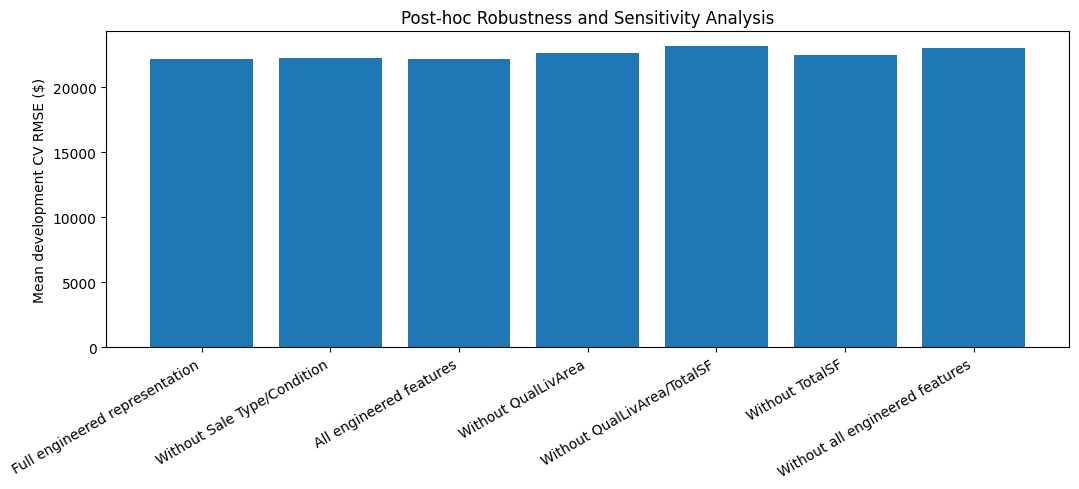

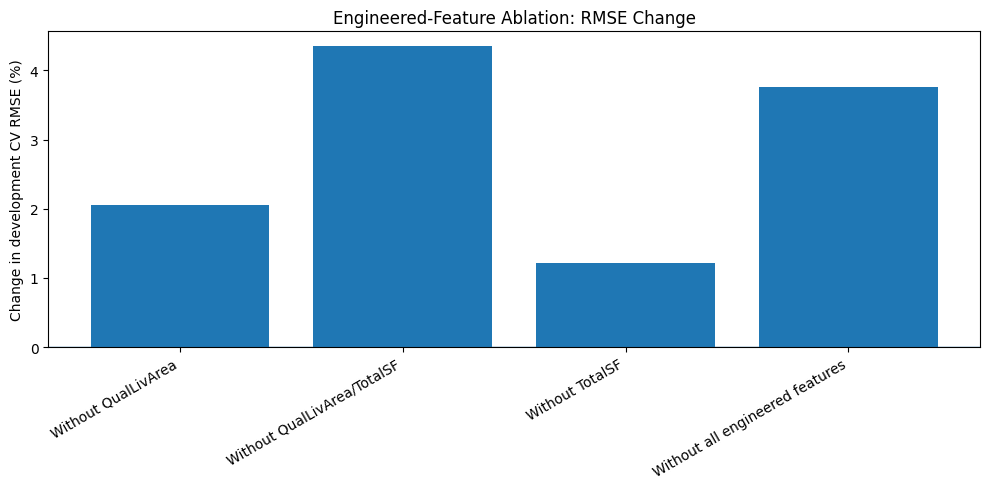

In [15]:
sale_for_combined = sale_summary.reset_index().assign(Study="Sale-context sensitivity")
ablation_for_combined = ablation_summary.reset_index().assign(Study="Engineered-feature ablation")
combined = pd.concat([sale_for_combined, ablation_for_combined], ignore_index=True, sort=False)
display(combined.round(3))
combined.to_csv(PROCESSED_DIR/"robustness_sensitivity_summary.csv",index=False)

plt.figure(figsize=(11,5))
plt.bar(combined["Analysis"],combined["RMSE_mean"])
plt.ylabel("Mean development CV RMSE ($)")
plt.title("Post-hoc Robustness and Sensitivity Analysis")
plt.xticks(rotation=30,ha="right")
plt.tight_layout()
plt.savefig(FIGURES_DIR/"robustness_sensitivity_rmse.png",dpi=300,bbox_inches="tight")
plt.show()

ablation_plot=ablation_summary.reset_index().query("Analysis != 'All engineered features'")
plt.figure(figsize=(10,5))
plt.bar(ablation_plot["Analysis"],ablation_plot["RMSE_change_pct"])
plt.axhline(0,linewidth=1)
plt.ylabel("Change in development CV RMSE (%)")
plt.title("Engineered-Feature Ablation: RMSE Change")
plt.xticks(rotation=30,ha="right")
plt.tight_layout()
plt.savefig(FIGURES_DIR/"engineered_feature_ablation_rmse_change.png",dpi=300,bbox_inches="tight")
plt.show()


## Interpretation rules

- Do not replace the frozen final XGBoost model because of this notebook.
- Do not report these development-CV results as new held-out test performance.
- If excluding sale-context variables has little effect, the project can argue that performance is reasonably robust to an earlier prediction scenario.
- If performance worsens materially, report that the intended deployment point must specify whether sale circumstances are known.
- If removing `QualLivArea` and `TotalSF` worsens performance, that supports their usefulness as engineered representations.
- If performance barely changes, report that their strong SHAP importance partly reflects redistribution of information already available in their component variables.
- These are empirical sensitivity findings for this dataset, not causal conclusions.


In [16]:
display(ablation_summary.round(3))

,MAE_mean,MAE_sd,RMSE_mean,RMSE_sd,R2_mean,R2_sd,MAE_change_pct,RMSE_change_pct,R2_change
Analysis,,,,,,,,,
All engineered features,13516.278,1230.580,22195.446,3521.745,0.922,0.017,0.000,0.000,0.000
Without QualLivArea,13944.448,1134.405,22652.043,2948.049,0.918,0.015,3.168,2.057,-0.003
Without QualLivArea/TotalSF,13931.636,947.628,23159.981,2443.329,0.915,0.012,3.073,4.346,-0.007
Without TotalSF,13648.435,1177.024,22466.575,3187.115,0.920,0.015,0.978,1.222,-0.002
Without all engineered features,13871.163,1032.410,23028.294,2792.838,0.915,0.015,2.626,3.752,-0.006
